# 2. Modelar, evaluar y pronosticar 28 días

**Objetivo:** producir una estimación diaria y cuantificar incertidumbre a partir de compras históricas.

Secuencia: variables causales → candidatos → selección temporal → calibración independiente de la selección → evaluación retrospectiva → reajuste final.

Cada tabla y figura se exporta a `resultados/` o `documentacion/figuras/`. Las funciones comentadas están en `src/modelos.py` y `src/evaluacion.py`; el notebook explica su significado y muestra las entradas y salidas. Los datos de prueba ya han sido examinados en el contexto de este ejercicio: el protocolo respeta el tiempo, pero **no constituye una nueva evaluación ciega**.

In [1]:
# La ruta funciona tanto al abrir notebooks/ como desde la raíz del proyecto.
from pathlib import Path
import sys, json
ROOT=Path.cwd() if (Path.cwd()/'sql').exists() else Path.cwd().parent
sys.path.insert(0,str(ROOT))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from src.configuracion import INICIO, FIN, SELECCION, CALIBRACION, PRUEBA, NIVEL, particiones
from src.datos import conectar, consultar, preparar, exportar
pd.set_option('display.max_columns',20)
pd.set_option('display.max_rows',35)
plt.rcParams.update({'figure.figsize':(12,4),'axes.grid':True,'axes.spines.top':False,'axes.spines.right':False})
(ROOT/'resultados').mkdir(exist_ok=True)
(ROOT/'documentacion/figuras').mkdir(parents=True,exist_ok=True)
con=conectar()  # read_only=True: el análisis no escribe en la base original.
def figura(nombre):
    plt.tight_layout()
    plt.savefig(ROOT/'documentacion/figuras'/f'{nombre}.png',dpi=140,bbox_inches='tight')
    plt.show()

from src.modelos import MODELOS, CONFIG_ML, BASICAS, AMPLIAS, predecir, evaluar, matrices
from src.evaluacion import metricas, calibrar, aplicar_intervalos, cobertura, totales_semanales
serie,calendario,variables=preparar(con)
y=serie.set_index('fecha').y.asfreq('D')
exportar(particiones(),'particiones')
# Manifestamos decisiones antes de ajustar cualquier candidato.
protocolo=dict(inicio=INICIO,fin=FIN,nivel=NIVEL,modelos=MODELOS,config_ml=CONFIG_ML,
    criterio='MAE sobre pares origen-horizonte de selección; desempate alfabético',
    intervalo_principal='relativo; absoluto como análisis paralelo sin selección en prueba',
    interpretacion='Evaluación retrospectiva de datos previamente conocidos')
(ROOT/'resultados/protocolo.json').write_text(json.dumps(protocolo,ensure_ascii=False,indent=2))
print(f'{len(serie)} días; {len(variables)} pares origen-horizonte para ML.')
print(f'{len(SELECCION)} emisiones de selección, {len(CALIBRACION)} de calibración y {len(PRUEBA)} de prueba.')

567 días; 13356 pares origen-horizonte para ML.
30 emisiones de selección, 12 de calibración y 5 de prueba.


## 1. Convertir la serie en ejemplos supervisados

Para un origen `o` y horizonte `h`, queremos aprender `historia hasta o + calendario de o+h → compras de o+h`.

Ejemplo: al cierre del martes, sabemos cuántas compras hubo ese martes. Ese valor es `lag_0`. Para predecir el miércoles, el último miércoles observado fue seis días atrás; para predecir el martes siguiente, el último martes es el origen. La consulta calcula correctamente ese desplazamiento para todos los horizontes.

Las medias móviles terminan en el origen. Las variables ampliadas incluyen los últimos siete días, la media de 91 días, relaciones de nivel, variabilidad y las últimas cuatro observaciones del mismo día de semana. Los primeros 90 días sirven como historial; todas las variantes ML usan exactamente las mismas filas para que la comparación sea controlada.

In [2]:
# Seleccionamos un ejemplo con SQL; real es etiqueta, nunca una variable predictora.
con.register('variables',variables)
ejemplo=con.execute('SELECT origen,fecha,h,lag_0,media_7,media_28,media_91,\n ultimo_mismo_dia,media_4_mismo_dia,real FROM variables\n WHERE origen=CAST(? AS DATE) AND h IN (1,7,28) ORDER BY h',[str(SELECCION[0].date())]).df()
display(ejemplo); exportar(ejemplo,'ejemplo_variables')
assert 'real' not in BASICAS and 'real' not in AMPLIAS
assert not variables[BASICAS+AMPLIAS].isna().any().any()
print('La historia se fija en el origen; el día objetivo y su patrón semanal dependen de h.')

,origen,fecha,h,lag_0,media_7,media_28,media_91,ultimo_mismo_dia,media_4_mismo_dia,real
0,2017-07-25,2017-07-26,1,153,131.142857,128.392857,117.098901,153,142.75,124
1,2017-07-25,2017-08-01,7,153,131.142857,128.392857,117.098901,153,158.75,165
2,2017-07-25,2017-08-22,28,153,131.142857,128.392857,117.098901,153,158.75,138


La historia se fija en el origen; el día objetivo y su patrón semanal dependen de h.


### Ejemplo: los indicadores llegan al modelo

El calendario no se queda en una tabla descriptiva. `sql/features.sql` lo une a cada par origen-horizonte. Consultamos el pronóstico emitido al cierre del 21 de noviembre de 2017: en h=3, la fecha objetivo es Black Friday. La columna `real` aparece para comprobar después qué ocurrió; **no** forma parte de las entradas de LightGBM. SARIMAX toma esas mismas columnas del calendario mediante `exogenas()` en `src/modelos.py`.

La presencia de `black_friday=1` no garantiza una predicción acertada: antes de esa fecha no había otro Black Friday en el período útil para aprender su magnitud.

In [3]:
# La consulta conserva la fecha de origen y la fecha objetivo de cada fila.
ejemplo_evento=consultar(con,'ejemplo_variables_evento.sql',
                        ['2017-11-21','2017-11-24','2017-11-28'])
display(ejemplo_evento)
exportar(ejemplo_evento,'ejemplo_variables_evento')
assert ejemplo_evento.loc[ejemplo_evento.fecha.eq(pd.Timestamp('2017-11-24')),
                          'black_friday'].iloc[0]==1
print('El calendario del objetivo se conoce; el valor real solo se consulta después para evaluar.')

,origen,fecha,h,dia_semana,festivo,black_friday,post_black_friday,fin_anio,lag_0,media_28,real
0,2017-11-21,2017-11-24,3,5,0,1,0,0,228,163.678571,1176
1,2017-11-21,2017-11-25,4,6,0,0,1,0,228,163.678571,499
2,2017-11-21,2017-11-26,5,7,0,0,1,0,228,163.678571,391
3,2017-11-21,2017-11-27,6,1,0,0,1,0,228,163.678571,403
4,2017-11-21,2017-11-28,7,2,0,0,1,0,228,163.678571,380


El calendario del objetivo se conoce; el valor real solo se consulta después para evaluar.


## 2. Evitar fuga: controlar la fecha de la etiqueta

No basta con exigir que el origen de una fila sea pasado. Si una fila emitida ayer intenta predecir dentro de 28 días, su etiqueta todavía es desconocida hoy.

Por eso, en cada ajuste se exige **`fecha_objetivo <= origen_del_ajuste`**. Las filas futuras se mantienen para obtener predicciones, pero sus valores reales no se entregan al modelo. Los notebooks pueden contener la serie completa para evaluar; las funciones de ajuste recortan estrictamente la información permitida.

In [4]:
# Inspeccionamos el primer ajuste: las etiquetas llegan como máximo a su origen.
train,futuro=matrices(variables,SELECCION[0])
display(pd.DataFrame([dict(filas_entrenamiento=len(train),ultima_etiqueta=train.fecha.max(),
    origen_ajuste=SELECCION[0],primer_objetivo=futuro.fecha.min(),ultimo_objetivo=futuro.fecha.max())]))
assert train.fecha.max()<=SELECCION[0]
assert futuro.fecha.min()>SELECCION[0]
print('Los pares reutilizan días reales: su cantidad no equivale a observaciones independientes.')

,filas_entrenamiento,ultima_etiqueta,origen_ajuste,primer_objetivo,ultimo_objetivo
0,1974,2017-07-25,2017-07-25,2017-07-26,2017-08-22


Los pares reutilizan días reales: su cantidad no equivale a observaciones independientes.


## 3. Qué aprende cada modelo

| Modelo | Regla o estructura | Para qué sirve |
|---|---|---|
| Ingenuo | Repite el último valor 28 veces | Referencia mínima |
| Estacional_7 | Repite los últimos siete días | Referencia que respeta el ciclo semanal |
| ETS_amortiguado | Nivel + tendencia amortiguada + estacionalidad de 7 días | Adaptación suave del patrón |
| SARIMAX_calendario | Logaritmo, errores ARIMA(1,1,1), calendario y día semanal | Dependencia temporal con regresores conocidos |
| LightGBM, cuatro variantes | Árboles pequeños con historia, calendario y horizonte | Relaciones no lineales y comparación controlada |

Los cuatro LightGBM usan los mismos 300 árboles, 7 hojas, tasa de aprendizaje 0,03, pérdida L1 y semilla. Cruzamos dos factores: variables básicas/ampliadas y objetivo absoluto/relativo. No hacemos una búsqueda extensa de hiperparámetros.

El objetivo absoluto es `y`. El relativo es `r = log(1+y) - log(1+media_28)`. La inversión es `y_hat = exp(r_hat) × (1+media_28) - 1`, usando siempre la media del origen. El logaritmo estabiliza escala, pero L1 en esta escala pondera los errores de manera distinta a L1 en pedidos; su utilidad debe comprobarse en pedidos.

L1 aproxima una **mediana condicional**, no automáticamente una media. La transformación inversa es monótona, pero puede dar valores negativos; el código los recorta explícitamente a cero.

In [5]:
# Ejemplo pedagógico de ida y vuelta, independiente del entrenamiento real.
media_ejemplo=200.0; pedidos_ejemplo=220.0
r_ejemplo=np.log1p(pedidos_ejemplo)-np.log1p(media_ejemplo)
recuperado=np.expm1(r_ejemplo+np.log1p(media_ejemplo))
print(f'Media reciente: {media_ejemplo:.0f}; objetivo: {pedidos_ejemplo:.0f}; r={r_ejemplo:.4f}.')
print(f'Invirtiendo la transformación recuperamos {recuperado:.1f} pedidos.')
print(f'Variables básicas: {len(BASICAS)}. Ampliadas: {len(AMPLIAS)}.')
display(pd.DataFrame([CONFIG_ML]))

Media reciente: 200; objetivo: 220; r=0.0949.
Invirtiendo la transformación recuperamos 220.0 pedidos.
Variables básicas: 16. Ampliadas: 36.


,objective,learning_rate,num_leaves,n_estimators,min_child_samples,reg_lambda,random_state,n_jobs,deterministic,force_col_wise,verbosity
0,regression_l1,0.03,7,300,40,1.0,2026,1,True,True,-1


## 4. Selección walk-forward: aprender del pasado y avanzar

En cada uno de los 30 orígenes se vuelve a entrenar desde cero con toda la historia permitida. Se predicen 28 días y se guardan los reales para calcular errores. Después avanzamos siete días.

El criterio principal es **MAE promedio sobre todos los pares origen-horizonte de selección**. Cada emisión tiene 28 pares, así que coincide con promediar los MAE de los orígenes. RMSE penaliza más los errores grandes; sMAPE expresa error relativo simétrico (de 0 a 200 %). Si real y predicción son cero, su contribución a sMAPE es cero.

Todas las fechas se conservan, incluidos picos. Las ventanas solapadas dan más peso a fechas centrales, pero representan distintas decisiones de pronóstico. Exportaremos también una métrica con igual peso por fecha.

In [6]:
# Este es el bloque de mayor tiempo de ejecución: 30 × 8 ajustes.
p_sel,aj_sel=evaluar(y,variables,calendario,SELECCION,MODELOS)
exportar(p_sel,'predicciones_seleccion'); exportar(aj_sel,'ajustes_seleccion')
m_sel=metricas(p_sel).sort_values(['MAE','modelo']).reset_index(drop=True)
exportar(m_sel,'metricas_seleccion'); display(m_sel.round(3))
ganador=m_sel.iloc[0].modelo
mejor_ml=m_sel[m_sel.modelo.str.startswith('LGBM')].iloc[0].modelo
print('Modelo seleccionado exclusivamente por MAE de selección:',ganador)
print('Mejor candidato ML en selección:',mejor_ml)

2017-07-25: 8 modelos, 28 horizontes.


2017-08-01: 8 modelos, 28 horizontes.


2017-08-08: 8 modelos, 28 horizontes.


2017-08-15: 8 modelos, 28 horizontes.


2017-08-22: 8 modelos, 28 horizontes.


...

2018-01-30: 8 modelos, 28 horizontes.


2018-02-06: 8 modelos, 28 horizontes.


2018-02-13: 8 modelos, 28 horizontes.


,modelo,MAE,RMSE,sMAPE,sesgo,n
0,SARIMAX_calendario,43.113,92.225,20.581,-18.171,840
1,LGBM_amplio_absoluto,51.146,102.384,23.591,-9.131,840
2,LGBM_base_absoluto,51.608,103.376,23.669,-8.972,840
3,ETS_amortiguado,53.639,104.962,24.776,-8.846,840
4,Estacional_7,56.643,122.938,25.742,-9.838,840
5,Ingenuo,58.824,101.804,27.858,13.067,840
6,LGBM_amplio_relativo,64.337,132.025,26.657,5.116,840
7,LGBM_base_relativo,66.564,139.193,26.900,8.382,840


Modelo seleccionado exclusivamente por MAE de selección: SARIMAX_calendario
Mejor candidato ML en selección: LGBM_amplio_absoluto


## 5. Identificar qué aporta cada componente

La comparación factorial permite observar el efecto de ampliar variables manteniendo el objetivo, y de expresar el objetivo en términos relativos manteniendo las variables. Una mejora corresponde al conjunto de variables ampliadas; no permite atribuirla a una sola variable sin un experimento adicional.

También calculamos diferencias de MAE por origen. Un promedio favorable no significa que el modelo gane en todos los períodos. Los orígenes se solapan; sus diferencias no se usan aquí como si fueran una muestra independiente para declarar significancia estadística.

,comparacion,referencia,candidato,diferencia_MAE,origenes_mejora,origenes
0,Variables con objetivo absoluto,LGBM_base_absoluto,LGBM_amplio_absoluto,-0.462,13,30
1,Variables con objetivo relativo,LGBM_base_relativo,LGBM_amplio_relativo,-2.227,17,30
2,Objetivo con variables básicas,LGBM_base_absoluto,LGBM_base_relativo,14.957,12,30
3,Objetivo con variables ampliadas,LGBM_amplio_absoluto,LGBM_amplio_relativo,13.191,13,30


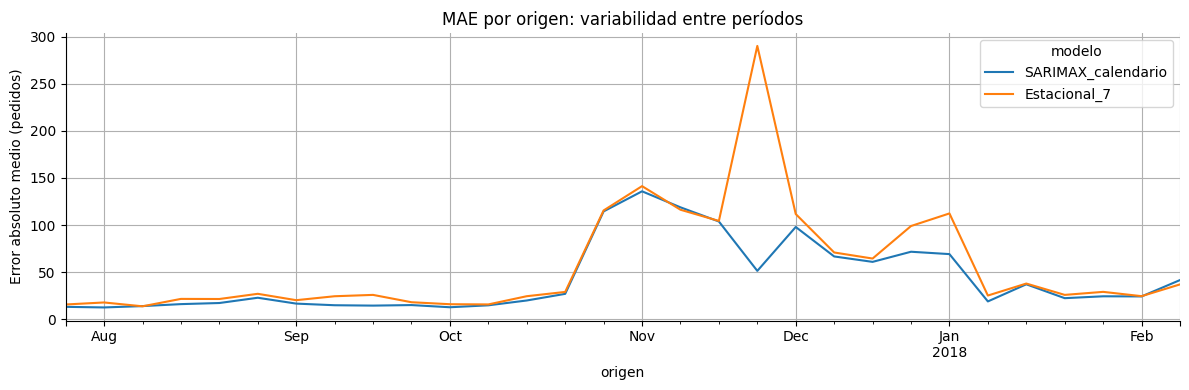

,modelo,origen,fecha,h,real,pred,error
3243,SARIMAX_calendario,2017-10-31,2017-11-24,24,1176,131.743602,1044.256398
3460,SARIMAX_calendario,2017-11-07,2017-11-24,17,1176,140.520447,1035.479553
3677,SARIMAX_calendario,2017-11-14,2017-11-24,10,1176,168.425852,1007.574148
3894,SARIMAX_calendario,2017-11-21,2017-11-24,3,1176,187.212006,988.787994
3244,SARIMAX_calendario,2017-10-31,2017-11-25,25,499,106.137588,392.862412
3461,SARIMAX_calendario,2017-11-07,2017-11-25,18,499,113.127690,385.872310
3678,SARIMAX_calendario,2017-11-14,2017-11-25,11,499,136.126919,362.873081
3895,SARIMAX_calendario,2017-11-21,2017-11-25,4,499,151.099782,347.900218


In [7]:
# Diferencia negativa: el segundo modelo tiene menor MAE.
por_origen=metricas(p_sel,('modelo','origen')); exportar(por_origen,'metricas_origen_seleccion')
pivote=por_origen.pivot(index='origen',columns='modelo',values='MAE')
comparaciones=[]
for referencia,candidato,idea in [
 ('LGBM_base_absoluto','LGBM_amplio_absoluto','Variables con objetivo absoluto'),
 ('LGBM_base_relativo','LGBM_amplio_relativo','Variables con objetivo relativo'),
 ('LGBM_base_absoluto','LGBM_base_relativo','Objetivo con variables básicas'),
 ('LGBM_amplio_absoluto','LGBM_amplio_relativo','Objetivo con variables ampliadas')]:
    d=pivote[candidato]-pivote[referencia]
    comparaciones.append(dict(comparacion=idea,referencia=referencia,candidato=candidato,
        diferencia_MAE=d.mean(),origenes_mejora=int((d<0).sum()),origenes=len(d)))
ablacion=pd.DataFrame(comparaciones); display(ablacion.round(3)); exportar(ablacion,'comparacion_componentes')
pivote[[ganador,'Estacional_7']].plot(title='MAE por origen: variabilidad entre períodos')
plt.ylabel('Error absoluto medio (pedidos)'); figura('mae_origen_seleccion')
# Errores grandes merecen una explicación concreta, no solo un promedio.
peores=p_sel[p_sel.modelo.eq(ganador)].assign(error=lambda d:abs(d.real-d.pred)).nlargest(8,'error')
display(peores); exportar(peores,'errores_mayores_seleccion')

## 6. Revisar convergencia y residuos estadísticos

SARIMAX registra la convergencia del optimizador en cada origen. Si el primer algoritmo no converge, se aplica una segunda estrategia fijada previamente; si tampoco converge, la ejecución se detiene. Los avisos se conservan en las tablas de ajustes.

La prueba Ljung–Box examina autocorrelación residual conjunta. Un p pequeño sugiere estructura que el modelo no absorbió. Un p grande no demuestra que el modelo sea correcto. Se muestran innovaciones estandarizadas, tras descartar la inicialización, en el primer origen para que el diagnóstico no use prueba.

,origen,convergencia,optimizador,Ljung_Box_p7,Ljung_Box_p14
3,2017-07-25,True,lbfgs,0.053859,0.220760
11,2017-08-01,True,lbfgs,0.035182,0.177019
19,2017-08-08,True,lbfgs,0.032049,0.162967
27,2017-08-15,True,lbfgs,0.025917,0.136159
35,2017-08-22,True,lbfgs,0.032860,0.150786
43,2017-08-29,True,lbfgs,0.036315,0.146557
51,2017-09-05,True,lbfgs,0.038249,0.137177
59,2017-09-12,True,lbfgs,0.029137,0.106076
67,2017-09-19,True,lbfgs,0.024368,0.076868
75,2017-09-26,True,lbfgs,0.033555,0.108195


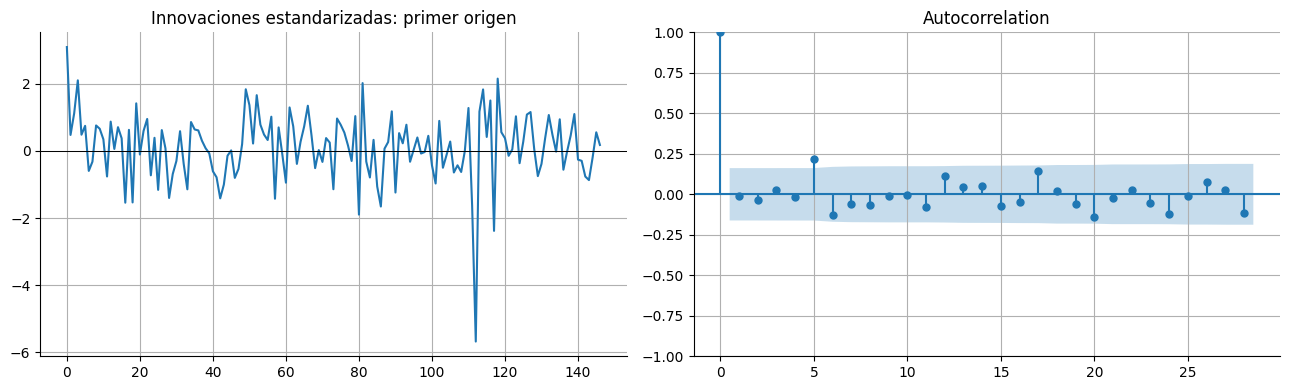

Avisos registrados en selección: 0
El AIC de ETS sobre pedidos no se compara directamente con SARIMAX sobre logaritmos.


In [8]:
# Ajuste del primer origen para visualizar residuos y sus límites.
from statsmodels.graphics.tsaplots import plot_acf
_,detalle_sar=predecir('SARIMAX_calendario',y,variables,calendario,SELECCION[0],detalles=True)
residuos=np.asarray(detalle_sar.pop('residuos'))
coeficientes=detalle_sar.pop('coeficientes')
(ROOT/'resultados/diagnostico_sarimax.json').write_text(json.dumps(detalle_sar,ensure_ascii=False,indent=2))
display(aj_sel[aj_sel.modelo.eq('SARIMAX_calendario')][['origen','convergencia','optimizador','Ljung_Box_p7','Ljung_Box_p14']])
fig,ax=plt.subplots(1,2,figsize=(13,4))
ax[0].plot(residuos); ax[0].axhline(0,color='black',linewidth=.7); ax[0].set_title('Innovaciones estandarizadas: primer origen')
plot_acf(residuos,lags=28,ax=ax[1]); figura('residuos_sarimax')
print('Avisos registrados en selección:',int(aj_sel.avisos.ne('').sum()))
print('El AIC de ETS sobre pedidos no se compara directamente con SARIMAX sobre logaritmos.')

## 7. Calibrar incertidumbre con una etapa reservada

El modelo ya está elegido. Ahora se reajusta en 12 orígenes posteriores que no participaron en la selección. Sus errores sirven para estimar márgenes.

Comparamos dos construcciones definidas de antemano: errores absolutos `|real-pred|` y errores relativos `|real-pred|/(1+pred)`. La principal es la relativa; la absoluta se informa como análisis paralelo sin escoger por su cobertura de prueba.

Para cada semana del horizonte ordenamos los errores y elegimos el elemento de rango `ceil((n+1)×0,90)`. En el caso diario hay 84 errores por grupo y se toma el número 77. El intervalo relativo es `pred ± q×(1+pred)`, limitado a cero por abajo.

La dependencia temporal, el solapamiento y el reajuste impiden prometer cobertura conformal exacta. El 90 % es un objetivo nominal que debemos contrastar con cobertura y amplitud observadas.

In [9]:
# El candidato ya está fijado; estos errores solo calibran incertidumbre.
p_cal,aj_cal=evaluar(y,variables,calendario,CALIBRACION,[ganador])
exportar(p_cal,'predicciones_calibracion'); exportar(aj_cal,'ajustes_calibracion')
cal_diaria={m:calibrar(p_cal,metodo=m) for m in ['absoluto','relativo']}
cal_semanal={m:calibrar(p_cal,metodo=m,semanal=True) for m in ['absoluto','relativo']}
cuantiles=pd.concat([*cal_diaria.values(),*cal_semanal.values()],ignore_index=True)
display(cuantiles); exportar(cuantiles,'cuantiles_intervalos')

2018-03-13: 1 modelos, 28 horizontes.


2018-03-20: 1 modelos, 28 horizontes.


2018-03-27: 1 modelos, 28 horizontes.


2018-04-03: 1 modelos, 28 horizontes.


2018-04-10: 1 modelos, 28 horizontes.


...

2018-05-08: 1 modelos, 28 horizontes.


2018-05-15: 1 modelos, 28 horizontes.


2018-05-22: 1 modelos, 28 horizontes.


2018-05-29: 1 modelos, 28 horizontes.


,semana,n,rango,cuantil,metodo,unidad,nivel
0,1,84,77,83.302416,absoluto,diaria,0.9
1,2,84,77,123.628532,absoluto,diaria,0.9
2,3,84,77,136.415493,absoluto,diaria,0.9
3,4,84,77,119.659302,absoluto,diaria,0.9
4,1,84,77,0.385935,relativo,diaria,0.9
5,2,84,77,0.609094,relativo,diaria,0.9
6,3,84,77,0.564199,relativo,diaria,0.9
7,4,84,77,0.540202,relativo,diaria,0.9
8,1,12,12,560.693953,absoluto,total_semanal,0.9
9,2,12,12,1174.687534,absoluto,total_semanal,0.9


## 8. Intervalos de totales semanales

Una semana operativa comprende h1–h7, la siguiente h8–h14, etc. Primero sumamos los siete valores reales y las siete predicciones; luego calculamos el error de ese **total**. Su cuantil produce un intervalo específico para la semana.

Aquí hay solo 12 residuos de total por posición semanal. Para 90 % el rango es 12: se utiliza el máximo de esos residuos. Es un cálculo finito y verificable, pero sensible a pocos episodios y a la dependencia entre emisiones.

**No sumamos límites diarios.** Por ejemplo, aunque cada intervalo diario cubra 80 %, la probabilidad de que los siete cubran a la vez puede ser muy distinta. Los intervalos semanales tampoco garantizan que las cuatro semanas queden cubiertas simultáneamente.

In [10]:
# Agrupamos puntos y reales antes de construir márgenes para totales.
totales_cal=totales_semanales(p_cal); display(totales_cal.head(8)); exportar(totales_cal,'totales_semanales_calibracion')
assert len(totales_cal)==len(CALIBRACION)*4
print('Cada fila es un total de siete días de una emisión, no un límite diario sumado.')

,modelo,origen,semana,desde,hasta,real,pred
0,SARIMAX_calendario,2018-03-13,1,2018-03-14,2018-03-20,1736.0,1543.085861
1,SARIMAX_calendario,2018-03-13,2,2018-03-21,2018-03-27,1633.0,1549.816939
2,SARIMAX_calendario,2018-03-13,3,2018-03-28,2018-04-03,1483.0,1511.259691
3,SARIMAX_calendario,2018-03-13,4,2018-04-04,2018-04-10,1515.0,1549.817171
4,SARIMAX_calendario,2018-03-20,1,2018-03-21,2018-03-27,1633.0,1760.884094
5,SARIMAX_calendario,2018-03-20,2,2018-03-28,2018-04-03,1483.0,1712.964548
6,SARIMAX_calendario,2018-03-20,3,2018-04-04,2018-04-10,1515.0,1756.914932
7,SARIMAX_calendario,2018-03-20,4,2018-04-11,2018-04-17,1646.0,1756.914932


Cada fila es un total de siete días de una emisión, no un límite diario sumado.


## 9. Prueba retrospectiva: las últimas ocho semanas útiles

Evaluamos del **27 de junio al 21 de agosto de 2018** mediante cinco emisiones. Son 140 pares por modelo y 56 fechas distintas. Los puntos centrales se pronostican hasta cuatro veces con anticipaciones diferentes.

Cada origen puede incorporar ventas de prueba que ya ocurrieron antes de esa emisión: eso reproduce un reajuste operativo legítimo. El candidato seleccionado y los cuantiles de intervalos permanecen fijados. No elegimos otro ganador por mirar esta tabla.

In [11]:
p_test,aj_test=evaluar(y,variables,calendario,PRUEBA,MODELOS)
exportar(p_test,'predicciones_prueba'); exportar(aj_test,'ajustes_prueba')
m_test=metricas(p_test).sort_values(['MAE','modelo']); display(m_test.round(3)); exportar(m_test,'metricas_prueba')
for etapa,p in [('seleccion',p_sel),('prueba',p_test)]:
    exportar(metricas(p,('modelo','h')),f'metricas_horizonte_{etapa}')
    exportar(metricas(p.assign(semana=(p.h-1)//7+1),('modelo','semana')),f'metricas_semana_{etapa}')
    exportar(metricas(p,('modelo','origen')),f'metricas_origen_{etapa}')
# Igual peso por fecha: primero promediamos pérdidas de sus emisiones, luego fechas.
con.register('predicciones',p_test)
igual_fecha=con.sql('WITH diario AS (SELECT modelo,fecha,\n avg(abs(real-pred)) mae,avg(pow(real-pred,2)) mse,\n avg(CASE WHEN abs(real)+abs(pred)=0 THEN 0 ELSE 200*abs(real-pred)/(abs(real)+abs(pred)) END) smape\n FROM predicciones GROUP BY 1,2)\n SELECT modelo,avg(mae) MAE,sqrt(avg(mse)) RMSE,avg(smape) sMAPE,count(*) fechas\n FROM diario GROUP BY 1 ORDER BY MAE').df()
display(igual_fecha.round(3)); exportar(igual_fecha,'metricas_prueba_igual_peso_fecha')
peso=con.sql("SELECT fecha,count(*) emisiones FROM predicciones WHERE modelo='Estacional_7' GROUP BY fecha ORDER BY fecha").df()
exportar(peso,'peso_fechas_prueba')
print(f'Ganador fijado en selección: {ganador}. Mejor MAE observado en prueba: {m_test.iloc[0].modelo}.')

2018-06-26: 8 modelos, 28 horizontes.


2018-07-03: 8 modelos, 28 horizontes.


2018-07-10: 8 modelos, 28 horizontes.


2018-07-17: 8 modelos, 28 horizontes.


2018-07-24: 8 modelos, 28 horizontes.


,modelo,MAE,RMSE,sMAPE,sesgo,n
0,ETS_amortiguado,65.080,80.495,31.014,-39.216,140
7,SARIMAX_calendario,65.823,81.293,31.255,-43.361,140
5,LGBM_base_absoluto,67.008,82.348,31.606,-41.923,140
1,Estacional_7,67.021,84.597,32.404,-39.979,140
3,LGBM_amplio_absoluto,67.322,83.086,31.934,-42.196,140
2,Ingenuo,68.221,84.065,31.487,-18.236,140
6,LGBM_base_relativo,69.309,86.531,33.122,-43.558,140
4,LGBM_amplio_relativo,70.435,86.425,33.427,-44.443,140


,modelo,MAE,RMSE,sMAPE,fechas
0,SARIMAX_calendario,58.182,73.991,27.732,56
1,ETS_amortiguado,58.201,73.472,27.861,56
2,Estacional_7,59.176,77.513,28.615,56
3,LGBM_base_absoluto,59.599,75.293,28.214,56
4,LGBM_amplio_absoluto,59.767,75.850,28.424,56
5,LGBM_base_relativo,61.934,79.770,29.792,56
6,LGBM_amplio_relativo,63.007,79.641,30.091,56
7,Ingenuo,64.783,80.032,30.084,56


Ganador fijado en selección: SARIMAX_calendario. Mejor MAE observado en prueba: ETS_amortiguado.


## 10. Leer errores por anticipación

MAE se expresa en pedidos, RMSE también y sMAPE en porcentaje. Una curva puede subir o bajar: no imponemos que el error crezca de forma monótona con el horizonte.

Las diferencias entre horizontes también dependen de qué fechas evalúa cada uno. En este experimento cada h de prueba tiene solo cinco emisiones. Una curva irregular es esperable y no debe interpretarse como una ley general.

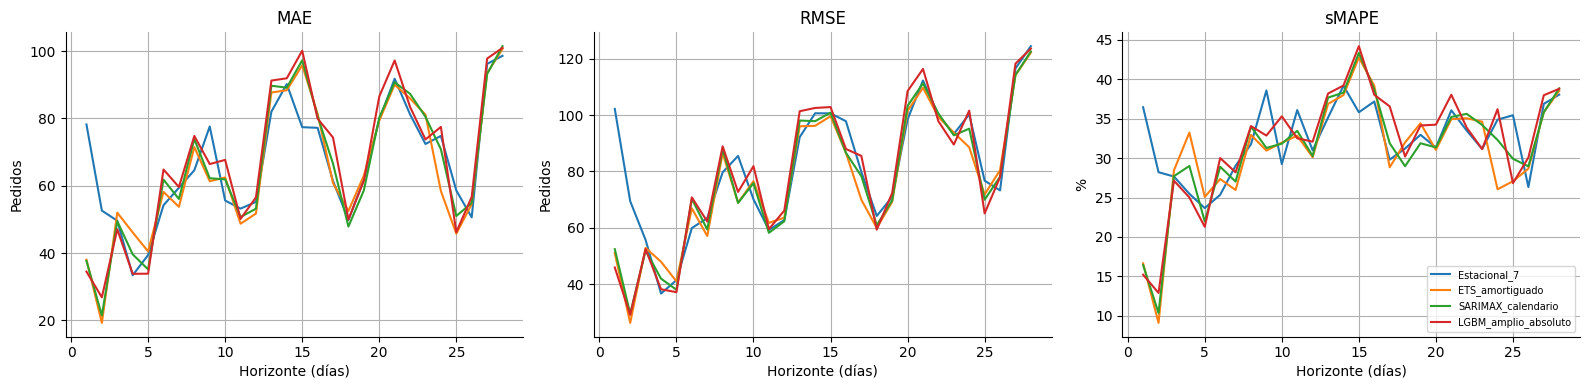

,modelo,semana,MAE,RMSE,sMAPE,sesgo,n
0,ETS_amortiguado,1,43.966,50.412,23.686,-5.457,35
1,ETS_amortiguado,2,67.395,79.669,33.379,-30.014,35
2,ETS_amortiguado,3,74.689,87.070,34.734,-52.430,35
3,ETS_amortiguado,4,74.270,97.201,32.258,-68.963,35
4,Estacional_7,1,52.400,64.403,27.975,-6.114,35
5,Estacional_7,2,68.343,79.877,34.422,-30.743,35
6,Estacional_7,3,71.286,90.678,33.478,-53.229,35
7,Estacional_7,4,76.057,99.379,33.741,-69.829,35
8,Ingenuo,1,53.057,64.257,26.677,15.629,35
9,Ingenuo,2,74.371,87.296,36.103,-9.000,35


In [12]:
# Comparamos representantes elegidos sin consultar su error de prueba.
representantes=list(dict.fromkeys(['Estacional_7','ETS_amortiguado','SARIMAX_calendario',mejor_ml,ganador]))
fig,ax=plt.subplots(1,3,figsize=(16,4))
por_h=metricas(p_test,('modelo','h'))
for eje,metrica in zip(ax,['MAE','RMSE','sMAPE']):
    for nombre in representantes:
        g=por_h[por_h.modelo.eq(nombre)]
        eje.plot(g.h,g[metrica],label=nombre)
    eje.set_title(metrica); eje.set_xlabel('Horizonte (días)')
ax[0].set_ylabel('Pedidos'); ax[1].set_ylabel('Pedidos'); ax[2].set_ylabel('%')
ax[2].legend(fontsize=7); figura('metricas_horizonte_prueba')
display(metricas(p_test.assign(semana=(p_test.h-1)//7+1),('modelo','semana')).round(3))

## 11. Medir cobertura y amplitud

Cobertura = proporción de reales que quedaron entre los límites. Amplitud = límite superior − inferior, en pedidos. Una cobertura alta con intervalos enormes puede tener poca utilidad operativa; ambas medidas deben leerse juntas.

En diario se evalúan 140 pares dependientes; en totales semanales, 20 pares. Informamos además por semana de horizonte para que un promedio global no oculte fallos concentrados. Los cuantiles no se recalibran con estos errores de prueba.

,metodo_intervalo,cubiertos,n,cobertura,ancho_medio
0,absoluto,123,140,0.878571,230.588392
1,relativo,107,140,0.764286,202.461957


,metodo_intervalo,cubiertos,n,cobertura,ancho_medio
0,absoluto,19,20,0.95,1812.876779
1,relativo,16,20,0.80,1578.662066


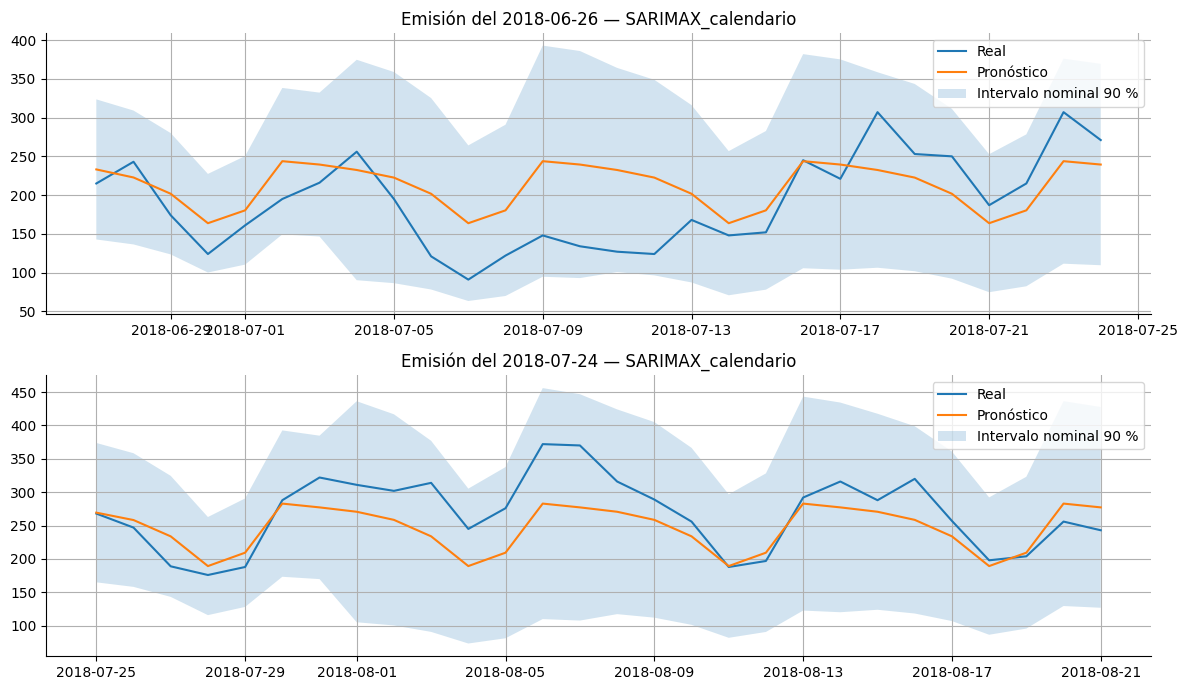

In [13]:
# Aplicamos cuantiles reservados: no se estiman con los errores de prueba.
seleccionado_test=p_test[p_test.modelo.eq(ganador)].copy()
i_test=pd.concat([aplicar_intervalos(seleccionado_test,cal_diaria[m]) for m in cal_diaria],ignore_index=True)
i_sem=pd.concat([aplicar_intervalos(seleccionado_test,cal_semanal[m],semanal=True) for m in cal_semanal],ignore_index=True)
exportar(i_test,'intervalos_diarios_prueba'); exportar(i_sem,'intervalos_semanales_prueba')
cov_d=cobertura(i_test); cov_s=cobertura(i_sem)
display(cov_d); display(cov_s)
exportar(cov_d,'cobertura_diaria'); exportar(cov_s,'cobertura_semanal')
exportar(cobertura(i_test,('metodo_intervalo','semana')),'cobertura_diaria_por_semana')
exportar(cobertura(i_sem,('metodo_intervalo','semana')),'cobertura_semanal_por_semana')
principal=i_test[i_test.metodo_intervalo.eq('relativo')]
fig,axes=plt.subplots(2,1,figsize=(12,7))
for eje,origen in zip(axes,[PRUEBA[0],PRUEBA[-1]]):
    g=principal[principal.origen.eq(origen)]
    eje.plot(g.fecha,g.real,label='Real'); eje.plot(g.fecha,g.pred,label='Pronóstico')
    eje.fill_between(g.fecha,g.inferior,g.superior,alpha=.2,label='Intervalo nominal 90 %')
    eje.set_title(f'Emisión del {origen.date()} — {ganador}'); eje.legend()
figura('evaluacion_intervalos')

## 12. Eventos y explicaciones prudentes

Black Friday y la huelga se conservan. La primera ventana de Black Friday 2017 ocurre cuando el modelo todavía no ha observado otro Black Friday en el tramo útil: un indicador conocido no permite aprender una magnitud sin ejemplos.

La huelga se encuentra en calibración; sus errores pueden aumentar los márgenes. Es parte del riesgo histórico conservado. Los promedios de eventos y del resto se refieren a épocas distintas y no son una estimación causal del efecto de esos eventos.

In [14]:
# Describimos períodos; esta comparación no identifica efectos causales.
eventos=consultar(con,'eventos.sql'); display(eventos); exportar(eventos,'descripcion_eventos')
con.register('p_cal',p_cal)
error_eventos=con.sql("SELECT CASE WHEN fecha BETWEEN DATE '2018-05-21' AND DATE '2018-05-31'\n THEN 'Ventana de huelga' ELSE 'Resto de calibración' END periodo,\n count(*) pares,count(DISTINCT fecha) fechas,avg(abs(real-pred)) MAE\n FROM p_cal GROUP BY 1 ORDER BY 1").df()
display(error_eventos); exportar(error_eventos,'errores_eventos_calibracion')

,periodo,dias,pedidos,media,minimo,maximo
0,Black Friday y cuatro días siguientes,5,2849.0,569.800000,380,1176
1,Huelga: ventana de análisis,11,1519.0,138.090909,99,206
2,Resto del período,551,93222.0,169.186933,35,372


,periodo,pares,fechas,MAE
0,Resto de calibración,292,94,38.807140
1,Ventana de huelga,44,11,119.512116


## 13. Pronóstico final histórico

Reajustamos el modelo seleccionado con todo el período útil hasta el 21 de agosto de 2018 y pronosticamos del **22 de agosto al 18 de septiembre de 2018**. Es una simulación histórica, no una proyección de Olist para la actualidad.

Mantenemos los cuantiles aprendidos en calibración para conservar trazabilidad. La distribución final puede diferir: su cobertura futura es desconocida. Los puntos son continuos aunque las compras reales sean enteras; redondeamos solo para presentar, conservando decimales en los archivos.

La suma de 28 pronósticos puntuales no es automáticamente la media esperada ni la mediana del total. Los intervalos semanales se obtienen de errores de totales y no se suman para anunciar cobertura mensual.

,fecha,h,pred,inferior,superior
0,2018-08-22,1,251.2,153.9,348.5
1,2018-08-23,2,243.5,149.1,337.8
2,2018-08-24,3,220.5,135.0,306.0
3,2018-08-25,4,178.5,109.2,247.8
4,2018-08-26,5,197.2,120.7,273.6
5,2018-08-27,6,266.9,163.5,370.3
6,2018-08-28,7,262.2,160.6,363.8
7,2018-08-29,8,255.6,99.3,411.8
8,2018-08-30,9,244.4,94.9,393.9
9,2018-08-31,10,220.7,85.7,355.7


,semana,desde,hasta,pred,inferior,superior
0,1,2018-08-22,2018-08-28,1620.0,972.0,2267.9
1,2,2018-08-29,2018-09-04,1625.5,454.0,2797.0
2,3,2018-09-05,2018-09-11,1589.5,623.6,2555.5
3,4,2018-09-12,2018-09-18,1625.5,614.3,2636.8


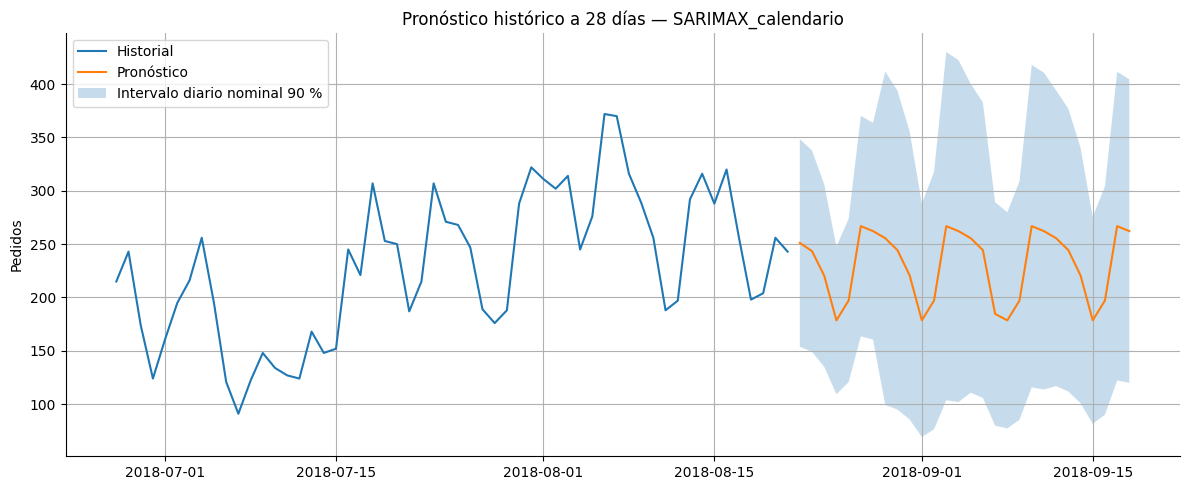

Suma de puntos a 28 días: 6,460.6 pedidos.


In [15]:
# El reajuste usa toda la historia útil; los reales futuros siguen vacíos.
origen_final=pd.Timestamp(FIN)
p_final,aj_final=predecir(ganador,y,variables,calendario,origen_final)
final=pd.DataFrame(dict(modelo=ganador,origen=origen_final,
    fecha=pd.date_range(origen_final+pd.Timedelta(days=1),periods=28),
    h=np.arange(1,29),real=np.nan,pred=p_final))
final_d=aplicar_intervalos(final,cal_diaria['relativo'])
final_s=aplicar_intervalos(final,cal_semanal['relativo'],semanal=True)
exportar(final_d,'pronostico_diario_28_dias'); exportar(final_s,'pronostico_semanal')
exportar(pd.DataFrame([aj_final]),'ajuste_final')
# Redondeamos solo columnas numéricas para presentar; los CSV conservan precisión.
vista_d=final_d[['fecha','h','pred','inferior','superior']].copy()
vista_s=final_s[['semana','desde','hasta','pred','inferior','superior']].copy()
for vista in [vista_d,vista_s]:
    vista[['pred','inferior','superior']]=vista[['pred','inferior','superior']].round(1)
    display(vista)
fig,ax=plt.subplots(figsize=(12,5))
# Usamos fechas datetime en ambas curvas para mantener la misma escala temporal.
ax.plot(y.index[-56:],y.iloc[-56:].to_numpy(),label='Historial')
ax.plot(final_d.fecha,final_d.pred,label='Pronóstico')
ax.fill_between(final_d.fecha,final_d.inferior,final_d.superior,alpha=.25,label='Intervalo diario nominal 90 %')
ax.set_title(f'Pronóstico histórico a 28 días — {ganador}'); ax.set_ylabel('Pedidos'); ax.legend()
figura('pronostico_final')
print(f'Suma de puntos a 28 días: {final.pred.sum():,.1f} pedidos.')

## 14. Interpretar LightGBM sin atribuir causalidad

La importancia por ganancia resume cuánto redujeron la pérdida las divisiones que usaron cada variable. Depende de variables correlacionadas y no indica que intervenir esa variable cause más ventas.

Se muestra para el mejor candidato ML elegido en selección, incluso si el ganador global pertenece a otra familia. Esto es una explicación del modelo, no un criterio adicional para elegirlo después de la prueba.

,variable,ganancia
11,tendencia,277515.31
8,dia_semana,58712.19
9,dia_mes,49610.57
10,mes,21663.42
26,media_4_mismo_dia,12355.24
15,fin_anio,8095.74
35,rel_media_4_dias,6793.04
14,post_black_friday,6667.26
12,festivo,5934.75
21,media_91,4952.25


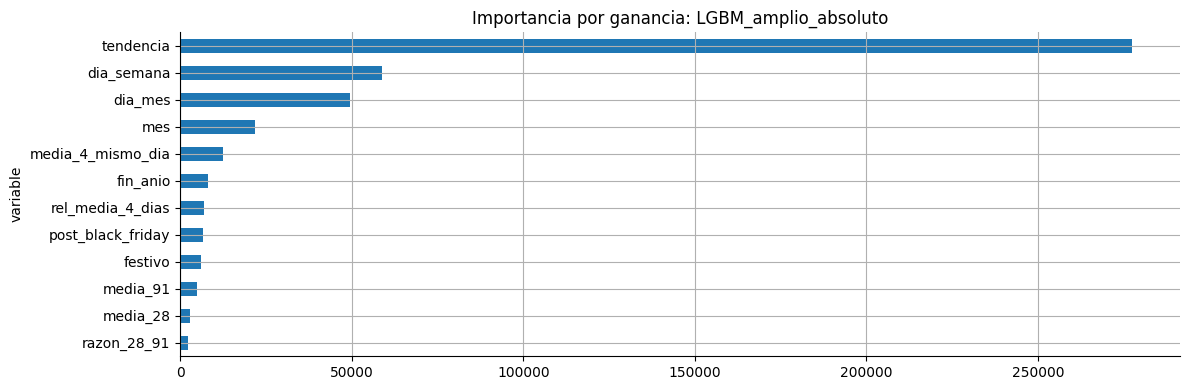

In [16]:
# La ganancia explica el ajuste de ML y no se interpreta como causalidad.
_,detalle_ml=predecir(mejor_ml,y,variables,calendario,origen_final,detalles=True)
importancia=pd.DataFrame(detalle_ml['importancia_gain'].items(),columns=['variable','ganancia']).sort_values('ganancia',ascending=False)
exportar(importancia,'importancia_variables'); display(importancia.head(12).round(2))
importancia.head(12).sort_values('ganancia').plot.barh(x='variable',y='ganancia',legend=False,title=f'Importancia por ganancia: {mejor_ml}')
figura('importancia_variables')

## 15. Conclusiones que se derivan de los resultados

Leemos primero el criterio de selección, luego la evaluación posterior y finalmente la incertidumbre. Un ganador de selección puede perder en prueba. Una transformación relativa puede ayudar o perjudicar según la muestra. El valor del ejercicio está en comprobarlo mediante un protocolo explícito.

La auditoría adicional concilia las métricas mediante SQL, verifica las ventanas, retira físicamente el futuro para reproducir ajustes y comprueba que los notebooks estén ejecutados sin errores.

In [17]:
# Las conclusiones se generan desde tablas para evitar cifras inconsistentes.
ms=m_sel.set_index('modelo'); mt=m_test.set_index('modelo')
cd=cov_d.set_index('metodo_intervalo').loc['relativo']
cs=cov_s.set_index('metodo_intervalo').loc['relativo']
resumen=dict(inicio=INICIO,fin=FIN,ganador=ganador,mejor_ml=mejor_ml,
    MAE_seleccion=float(ms.loc[ganador,'MAE']),MAE_prueba=float(mt.loc[ganador,'MAE']),
    MAE_estacional_prueba=float(mt.loc['Estacional_7','MAE']),
    mejor_prueba=m_test.iloc[0].modelo,cobertura_diaria=float(cd.cobertura),
    cubiertos_diarios=int(cd.cubiertos),n_diarios=int(cd.n),
    cobertura_semanal=float(cs.cobertura),cubiertos_semanales=int(cs.cubiertos),n_semanales=int(cs.n),
    total_puntos_28_dias=float(final.pred.sum()),n_dias=len(serie),total_pedidos=int(serie.y.sum()),
    interpretacion='Retrospectiva; los datos de prueba ya eran conocidos. Sin garantía de cobertura futura.')
(ROOT/'resultados/resumen.json').write_text(json.dumps(resumen,ensure_ascii=False,indent=2))
display(Markdown(f"""**Selección:** {ganador}, MAE {resumen['MAE_seleccion']:.2f} pedidos.


**Prueba:** MAE {resumen['MAE_prueba']:.2f}; referencia semanal {resumen['MAE_estacional_prueba']:.2f}.


**Incertidumbre relativa:** cobertura diaria {cd.cobertura:.1%} ({int(cd.cubiertos)}/{int(cd.n)} pares);
semanal {cs.cobertura:.1%} ({int(cs.cubiertos)}/{int(cs.n)} totales). Nivel nominal 90 %.


**Pronóstico final:** suma de puntos {final.pred.sum():,.1f}; se debe leer junto a sus intervalos y límites históricos."""))
if cd.cobertura < NIVEL:
    print('El intervalo relativo principal NO alcanzó el 90 % nominal en prueba.')
    print('Sus límites finales son experimentales; no se presentan como cobertura futura validada.')
print('La tabla de prueba describe rendimiento posterior y no redefine la elección previa.')
con.close()

**Selección:** SARIMAX_calendario, MAE 43.11 pedidos.


**Prueba:** MAE 65.82; referencia semanal 67.02.


**Incertidumbre relativa:** cobertura diaria 76.4% (107/140 pares);
semanal 80.0% (16/20 totales). Nivel nominal 90 %.


**Pronóstico final:** suma de puntos 6,460.6; se debe leer junto a sus intervalos y límites históricos.

El intervalo relativo principal NO alcanzó el 90 % nominal en prueba.
Sus límites finales son experimentales; no se presentan como cobertura futura validada.
La tabla de prueba describe rendimiento posterior y no redefine la elección previa.


## Preguntas para defender el ejercicio

1. **¿Qué se predice?** Órdenes registradas por día, a partir del cierre de un origen.
2. **¿Por qué no barajar días?** Porque permitiría que el entrenamiento conociera el futuro del ejemplo evaluado.
3. **¿Por qué filtrar fecha objetivo?** Una fila de origen pasado puede tener una etiqueta todavía futura.
4. **¿Por qué dos referencias simples?** Para saber cuánto valor añade la complejidad frente a reglas comprensibles.
5. **¿Qué significa MAE=40?** Un error absoluto promedio de 40 pedidos por par evaluado; no un máximo de 40.
6. **¿90 % garantiza cada semana?** No: es nominal y depende de estabilidad, muestra y dependencia.
7. **¿Se puede sumar un intervalo diario?** No para atribuir automáticamente la misma cobertura al total.
8. **¿El modelo ganador sirve siempre?** Su rendimiento es específico del protocolo y período; se necesita evaluación posterior y monitoreo.